# **Logistic Regression and Softmax Regression (Classification) - Diabetes Dataset**

| | Logistic Regression | Softmax Regression |
|---|---|---|
| Classes | **2** (binary) | **3 or more** (multi-class) |
| Output function | sigmoid: `1 / (1 + e^-z)` | softmax: `e^zk / sum(e^zj)` |
| Output | probability of class 1 | one probability per class (sum = 1) |
| Here | **Part A:** `diabetes` (0 / 1) | **Part B:** age group (3 classes) |

Softmax regression is the multi-class version of logistic regression. With only 2 classes, softmax gives exactly the same result as logistic regression.

**Part A (Logistic):** target `diabetes`. Only ~9% of rows are diabetic, so this is an **imbalanced** problem. We handle it with a stratified split + CV, `class_weight`, and **threshold tuning**.

**Part B (Softmax):** the `diabetes` column has only 2 classes, so for softmax we build a 3-class target from `age` (Young / Middle / Senior) and predict it from the other columns. This is a demo target made for learning softmax; it is not a medical target.

Data: `diabetes_after_preprocessing.csv` (already encoded and scaled, 96,030 rows).

### 1. Import

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             precision_recall_curve, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)

### 2. Load data

In [2]:
df = pd.read_csv('../1. Data_Preprocessing/For_Classification/diabetes_after_preprocessing.csv')
print(df.shape)
df.head()

(96030, 12)


,age,bmi,hba1c_level,blood_glucose_level,hypertension,heart_disease,gender_male,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_unknown,diabetes
0,1.701773,-0.310755,0.994239,0.043415,0,1,0.0,0.0,0.0,1.0,0.0,0
1,0.544112,0.048864,0.994239,-1.422971,0,0,0.0,0.0,0.0,0.0,1.0,0
2,-0.613548,0.048864,0.155650,0.483331,0,0,1.0,0.0,0.0,1.0,0.0,0
3,-0.257345,-0.604528,-0.496585,0.410012,0,0,0.0,0.0,0.0,0.0,0.0,0
4,1.523671,-1.163373,-0.682938,0.410012,1,1,1.0,0.0,0.0,0.0,0.0,0


# PART A: Logistic Regression (binary)
### 3. Check imbalance

diabetes
0    87548
1     8482
diabetes
0    91.2 %
1     8.8 %
Name: count, dtype: str


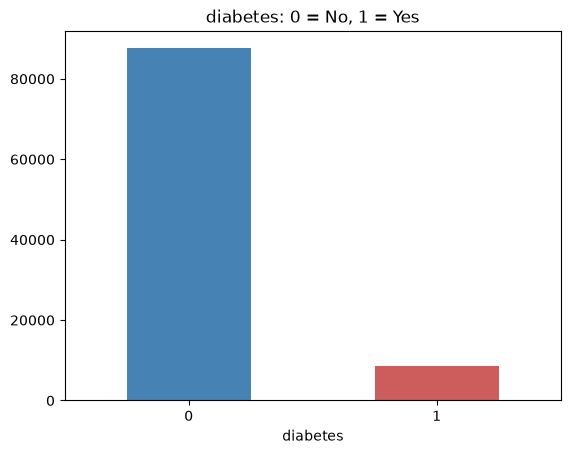

In [3]:
x = df.drop('diabetes', axis=1)
y = df['diabetes']

counts = y.value_counts()
print(counts.to_string())
print((counts / len(y) * 100).round(1).astype(str) + ' %')

counts.plot(kind='bar', color=['steelblue', 'indianred'], rot=0, title='diabetes: 0 = No, 1 = Yes')
plt.show()

Only ~9% are diabetic. A model that always says "No diabetes" would be 91% accurate but useless, so **accuracy is a bad metric here**. We look at **recall, precision, F1 and ROC-AUC**.

### 4. Stratified split and CV
`stratify=y` keeps the same 9% diabetic ratio in train, test and every CV fold.

In [4]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)
print(x_train.shape, x_test.shape)
print('Diabetic % train:', round(y_train.mean() * 100, 2), '| test:', round(y_test.mean() * 100, 2))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

(76824, 11) (19206, 11)
Diabetic % train: 8.83 | test: 8.83


### 5. Tune Logistic Regression (GridSearchCV)
- `C` : inverse of regularization strength (small C = strong regularization)
- `penalty` : `l2` (Ridge-style) or `l1` (Lasso-style, can set weak feature weights to 0)

Scored with **ROC-AUC**, which does not depend on the 0.5 threshold and is not fooled by imbalance. (Features are already scaled, so no scaler is needed.)

In [5]:
%%time
param_grid = {'C': np.logspace(-3, 2, 11), 'penalty': ['l1', 'l2']}

grid = GridSearchCV(LogisticRegression(solver='liblinear', max_iter=1000),
                    param_grid, cv=cv, scoring='roc_auc', n_jobs=-1, return_train_score=True)
grid.fit(x_train, y_train)

print('Best Params   :', grid.best_params_)
print('Best CV AUC   :', round(grid.best_score_, 4))
print('Train AUC     :', round(grid.cv_results_['mean_train_score'][grid.best_index_], 4))

Best Params   : {'C': np.float64(0.31622776601683794), 'penalty': 'l2'}
Best CV AUC   : 0.962
Train AUC     : 0.9621
CPU times: total: 10.6 s
Wall time: 36.3 s


### 6. Handle imbalance: 3 strategies compared
1. **Plain** model, default threshold 0.5
2. **`class_weight='balanced'`**: mistakes on the rare diabetic class cost more
3. **Plain + tuned threshold**: keep the model, but choose the probability cut-off that gives the best F1 (found with CV predictions on the training data only)

In [6]:
best_params = grid.best_params_
plain    = LogisticRegression(solver='liblinear', max_iter=1000, **best_params)
balanced = LogisticRegression(solver='liblinear', max_iter=1000, class_weight='balanced', **best_params)

# ---- tuned threshold for the plain model (from out-of-fold probabilities) ----
oof_proba = cross_val_predict(plain, x_train, y_train, cv=cv, method='predict_proba')[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof_proba)
f1_curve = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
best_thr = thr[np.argmax(f1_curve)]
print('Best threshold (max CV F1):', round(best_thr, 3))

def scores(name, y_true, proba, threshold):
    pred = (proba >= threshold).astype(int)
    return {'Strategy': name, 'Threshold': round(threshold, 3),
            'Accuracy': accuracy_score(y_true, pred), 'Precision': precision_score(y_true, pred),
            'Recall': recall_score(y_true, pred), 'F1': f1_score(y_true, pred),
            'ROC_AUC': roc_auc_score(y_true, proba)}

plain.fit(x_train, y_train)
balanced.fit(x_train, y_train)
p_plain = plain.predict_proba(x_test)[:, 1]
p_bal   = balanced.predict_proba(x_test)[:, 1]

compare = pd.DataFrame([
    scores('1. Plain (threshold 0.5)',         y_test, p_plain, 0.5),
    scores('2. class_weight=balanced (0.5)',   y_test, p_bal,   0.5),
    scores('3. Plain + tuned threshold',       y_test, p_plain, best_thr),
]).set_index('Strategy')
compare.round(4)

Best threshold (max CV F1): 0.44


,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC
Strategy,,,,,,
1. Plain (threshold 0.5),0.50,0.9581,0.8626,0.6256,0.7252,0.9593
2. class_weight=balanced (0.5),0.50,0.8863,0.4293,0.8721,0.5754,0.9595
3. Plain + tuned threshold,0.44,0.9565,0.8238,0.6450,0.7235,0.9593


**How to read it:**
- **1. Plain:** high precision, but it misses about 37% of diabetic patients (recall ~0.63).
- **2. Balanced:** recall jumps to ~0.87 (it finds most diabetic patients), but precision drops to ~0.43 (many false alarms), so F1 is lower.
- **3. Tuned threshold:** almost the same as plain, because the F1-best cut-off is already close to 0.5 for this data.
- ROC-AUC is the same for all three, because the ranking of patients does not change; only the cut-off / weighting changes.

So the choice depends on the goal: **best balance (F1) -> strategy 1 or 3**; **catch as many diabetic patients as possible -> strategy 2 or a lower threshold**. The table below shows the trade-off for different thresholds.

In [7]:
rows = []
for t in [0.5, 0.4, 0.3, 0.2, 0.1]:
    pred = (p_plain >= t).astype(int)
    rows.append({'Threshold': t, 'Precision': precision_score(y_test, pred), 'Recall': recall_score(y_test, pred),
                 'F1': f1_score(y_test, pred), 'Missed diabetic': int(((pred == 0) & (y_test == 1)).sum()),
                 'False alarms': int(((pred == 1) & (y_test == 0)).sum())})
pd.DataFrame(rows).set_index('Threshold').round(3)

,Precision,Recall,F1,Missed diabetic,False alarms
Threshold,,,,,
0.5,0.863,0.626,0.725,635,169
0.4,0.797,0.660,0.722,577,285
0.3,0.716,0.707,0.711,497,476
0.2,0.599,0.771,0.674,388,876
0.1,0.450,0.848,0.588,258,1759


### 7. Final Logistic model = Plain model + tuned threshold (best F1)
Change `final_threshold` below if you prefer more recall (for example 0.3).

              precision    recall  f1-score   support

 No diabetes       0.97      0.99      0.98     17510
    Diabetes       0.82      0.65      0.72      1696

    accuracy                           0.96     19206
   macro avg       0.90      0.82      0.85     19206
weighted avg       0.95      0.96      0.95     19206



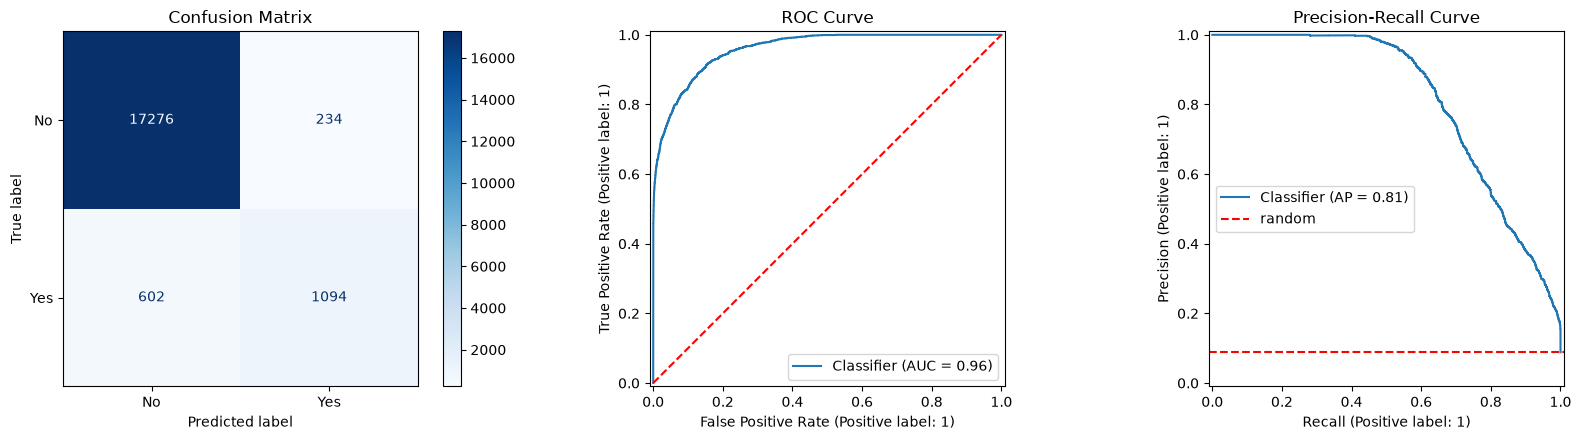

In [8]:
final_threshold = best_thr          # <- change this to trade precision for recall
final_pred = (p_plain >= final_threshold).astype(int)

print(classification_report(y_test, final_pred, target_names=['No diabetes', 'Diabetes']))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, final_pred, display_labels=['No', 'Yes'], cmap='Blues', ax=ax[0])
ax[0].set_title('Confusion Matrix')
RocCurveDisplay.from_predictions(y_test, p_plain, ax=ax[1]); ax[1].plot([0, 1], [0, 1], 'r--')
ax[1].set_title('ROC Curve')
PrecisionRecallDisplay.from_predictions(y_test, p_plain, ax=ax[2])
ax[2].axhline(y_test.mean(), color='r', ls='--', label='random'); ax[2].legend(); ax[2].set_title('Precision-Recall Curve')
plt.tight_layout(); plt.show()

### 8. Which features matter? (coefficients and odds ratio)
Features are scaled, so the coefficients can be compared directly.
`odds ratio = e^coefficient`: above 1 means the feature **increases** diabetes odds, below 1 **decreases** them.

,Coefficient,Odds_Ratio
hba1c_level,2.461,11.714
blood_glucose_level,1.353,3.870
age,1.037,2.822
heart_disease,0.725,2.065
hypertension,0.714,2.042
bmi,0.672,1.958
gender_male,0.256,1.292
smoking_history_ever,-0.142,0.867
smoking_history_never,-0.173,0.842
smoking_history_former,-0.177,0.838


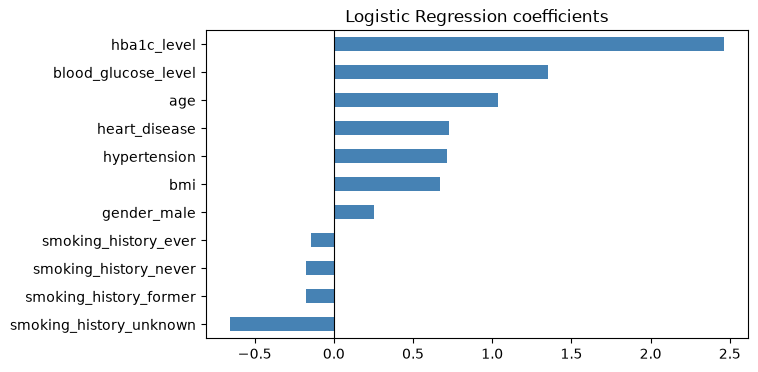

In [9]:
coef = pd.DataFrame({'Coefficient': plain.coef_[0], 'Odds_Ratio': np.exp(plain.coef_[0])}, index=x.columns)
coef = coef.sort_values('Coefficient', ascending=False)
display(coef.round(3))

coef['Coefficient'].sort_values().plot(kind='barh', color='steelblue', figsize=(7, 4), title='Logistic Regression coefficients')
plt.axvline(0, color='k', lw=0.8); plt.show()

### 9. Save the Logistic model (.pkl)
The model is trained on all data. The threshold is saved with it, because the model needs it to make correct yes / no decisions.

In [10]:
final_logistic = clone(plain).fit(x, y)

package = {'model': final_logistic, 'threshold': float(final_threshold), 'features': list(x.columns)}
joblib.dump(package, 'logistic_diabetes_model.pkl')

#Load and predict
pkg = joblib.load('logistic_diabetes_model.pkl')
proba = pkg['model'].predict_proba(x_test.iloc[:5][pkg['features']])[:, 1]
print('Diabetes probability:', proba.round(3))
print('Prediction          :', (proba >= pkg['threshold']).astype(int))
print('Actual              :', y_test.iloc[:5].values)

Diabetes probability: [0.029 0.043 0.    0.299 0.   ]
Prediction          : [0 0 0 0 0]
Actual              : [0 0 0 1 0]


# PART B: Softmax Regression (multi-class)
### 10. Softmax in 3 lines
Softmax turns raw scores into probabilities that sum to 1. With 2 classes it is the same as the sigmoid.

In [11]:
def softmax(z):
    e = np.exp(z - np.max(z))          # subtract max for numerical stability
    return e / e.sum()

scores_3 = np.array([2.0, 1.0, 0.1])
print('3 classes:', softmax(scores_3).round(3), '| sum =', softmax(scores_3).sum())

# 2 classes: softmax([0, z]) == sigmoid(z)
z = 1.5
print('2 classes softmax :', softmax(np.array([0, z]))[1].round(4))
print('sigmoid           :', (1 / (1 + np.exp(-z))).round(4), ' <- same, so logistic = softmax with 2 classes')

3 classes: [0.659 0.242 0.099] | sum = 1.0
2 classes softmax : 0.8176
sigmoid           : 0.8176  <- same, so logistic = softmax with 2 classes


### 11. Build the 3-class target (age group)
The age column is standardized, so we cut it into 3 equal-size groups (tertiles): **Young / Middle / Senior**. `age` is then removed from the features, otherwise the model would just read the answer.

In [12]:
age_group = pd.qcut(df['age'], q=3, labels=[0, 1, 2]).astype(int)       # 0 = Young, 1 = Middle, 2 = Senior
class_names = ['Young', 'Middle', 'Senior']

xs = df.drop(columns=['age'])         # features (includes diabetes, bmi, hypertension, ...)
ys = age_group
print(ys.value_counts().sort_index().rename(dict(enumerate(class_names))).to_string())

xs_train, xs_test, ys_train, ys_test = train_test_split(xs, ys, test_size=0.2, random_state=42, stratify=ys)
cv_s = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

age
Young     32397
Middle    32695
Senior    30938


### 12. Tune Softmax Regression
For more than 2 classes, `LogisticRegression` with the `lbfgs` solver is **softmax regression** (one weight vector per class). Only `C` is tuned here; scored with **macro F1** (average F1 of all 3 classes).

In [13]:
%%time
grid_s = GridSearchCV(LogisticRegression(solver='lbfgs', max_iter=2000),
                      {'C': np.logspace(-4, 2, 13)}, cv=cv_s, scoring='f1_macro', n_jobs=-1, return_train_score=True)
grid_s.fit(xs_train, ys_train)

softmax_model = grid_s.best_estimator_
print('Best Params     :', grid_s.best_params_)
print('Best CV macro F1:', round(grid_s.best_score_, 4))
print('Train macro F1  :', round(grid_s.cv_results_['mean_train_score'][grid_s.best_index_], 4))

Best Params     : {'C': np.float64(0.0031622776601683794)}
Best CV macro F1: 0.5464
Train macro F1  : 0.5464
CPU times: total: 6.86 s
Wall time: 14.4 s


### 13. Evaluate Softmax on the test set

Accuracy   : 0.5477 (guessing one class: 0.3405)
Macro F1   : 0.5447

              precision    recall  f1-score   support

       Young       0.56      0.69      0.62      6479
      Middle       0.48      0.47      0.47      6539
      Senior       0.62      0.48      0.54      6188

    accuracy                           0.55     19206
   macro avg       0.55      0.55      0.54     19206
weighted avg       0.55      0.55      0.54     19206



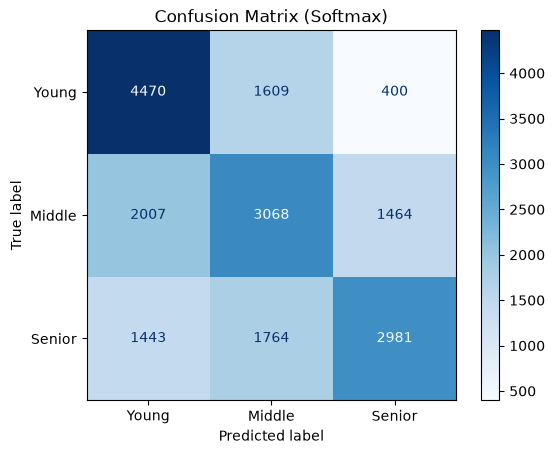

In [14]:
ys_pred = softmax_model.predict(xs_test)
baseline = DummyClassifier(strategy='most_frequent').fit(xs_train, ys_train).predict(xs_test)

print('Accuracy   :', round(accuracy_score(ys_test, ys_pred), 4), f'(guessing one class: {accuracy_score(ys_test, baseline):.4f})')
print('Macro F1   :', round(f1_score(ys_test, ys_pred, average="macro"), 4))
print()
print(classification_report(ys_test, ys_pred, target_names=class_names))

ConfusionMatrixDisplay.from_predictions(ys_test, ys_pred, display_labels=class_names, cmap='Blues')
plt.title('Confusion Matrix (Softmax)'); plt.show()

### 14. Softmax output: one probability per class (sum = 1)

In [15]:
proba = softmax_model.predict_proba(xs_test.iloc[:5])
out = pd.DataFrame(proba, columns=[f'P({c})' for c in class_names]).round(3)
out['Sum'] = proba.sum(axis=1)
out['Predicted'] = [class_names[i] for i in proba.argmax(axis=1)]
out['Actual'] = [class_names[i] for i in ys_test.iloc[:5]]
out

,P(Young),P(Middle),P(Senior),Sum,Predicted,Actual
0,0.022,0.478,0.500,1.0,Senior,Middle
1,0.547,0.247,0.206,1.0,Young,Young
2,0.108,0.364,0.528,1.0,Senior,Senior
3,0.124,0.316,0.560,1.0,Senior,Senior
4,0.436,0.310,0.254,1.0,Young,Senior


### 15. Softmax weights: one row per class
Each class has its own weight for each feature. A positive weight pushes the prediction toward that class.

,bmi,hba1c_level,blood_glucose_level,hypertension,heart_disease,gender_male,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_unknown,diabetes
Young,-0.562,-0.029,-0.017,-0.917,-0.719,0.096,-0.176,-0.335,0.117,0.502,-0.698
Middle,0.349,0.007,-0.007,0.037,-0.336,-0.051,-0.045,-0.248,-0.197,-0.478,-0.086
Senior,0.213,0.022,0.024,0.880,1.054,-0.045,0.221,0.583,0.080,-0.024,0.783


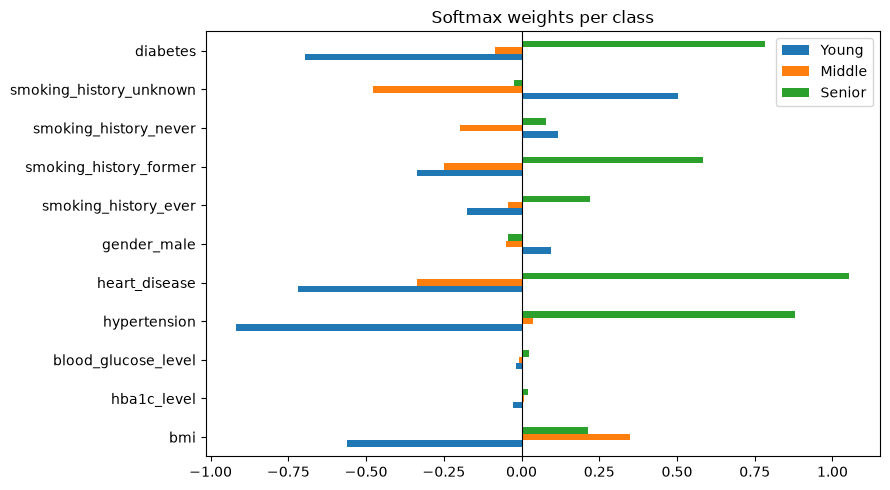

In [16]:
w = pd.DataFrame(softmax_model.coef_, index=class_names, columns=xs.columns)
display(w.round(3))

w.T.plot(kind='barh', figsize=(9, 5), title='Softmax weights per class')
plt.axvline(0, color='k', lw=0.8); plt.tight_layout(); plt.show()

### 16. Save the Softmax model (.pkl)

In [17]:
final_softmax = clone(softmax_model).fit(xs, ys)
joblib.dump({'model': final_softmax, 'classes': class_names, 'features': list(xs.columns)}, 'softmax_agegroup_model.pkl')

pkg = joblib.load('softmax_agegroup_model.pkl')
pred = pkg['model'].predict(xs_test.iloc[:5][pkg['features']])
print('Predicted:', [pkg['classes'][i] for i in pred])
print('Actual   :', [pkg['classes'][i] for i in ys_test.iloc[:5]])

Predicted: ['Senior', 'Young', 'Senior', 'Senior', 'Young']
Actual   : ['Middle', 'Young', 'Senior', 'Senior', 'Senior']


### 17. Download (Google Colab only)

In [18]:
try:
    from google.colab import files
    files.download('logistic_diabetes_model.pkl')
    files.download('softmax_agegroup_model.pkl')
except ImportError:
    print('Not Colab - files are saved in the notebook folder.')

Not Colab - files are saved in the notebook folder.
